# Investigação do AdaBoost (autor: marina)

Notebook de investigação do `AdaBoostClassifier`, comparável com os demais modelos do grupo:
mesma tabela `features`, mesma divisão (treino 2021–2022, validação 2023), mesmos folds
temporais (`src/modelagem/validacao.py`), mesmas métricas (PR-AUC principal, Recall@50,
Recall@100, ROC-AUC; `ARCHITECTURE.md`, seção 5) e semente 42. Todas as funções de treino e
avaliação vêm de `src.modelagem.treino` e `src.modelagem.pipeline`; o que é novo fica aqui.

Regras deste notebook:

- O **teste de 2024 não é usado** aqui, nem para olhar: a parte `teste` é descartada logo no setup.
  Ele pertence só ao `registrar_campeao` oficial.
- A melhor configuração é escolhida pelo **PR-AUC médio da CV temporal**. A validação de 2023 é
  reportada, mas não escolhe hiperparâmetro.
- Todo run no MLflow leva as tags `autor=marina` e `modelo=adaboost`. Os pisos (Regressão
  Logística padrão e heurística de recorrência) são calculados aqui **sem** registrar runs, para
  não duplicar os runs oficiais do experimento `01_baseline`.

Execução (dentro do container, como os notebooks 01 e 02):

```bash
docker compose --profile dev run --rm -T -v "$PWD/reports:/app/reports" -w /app/notebooks jupyter \
    jupyter nbconvert --to notebook --execute --inplace modelo_adaboost.ipynb --ExecutePreprocessor.timeout=-1
```

## 1. Setup

In [1]:
from pathlib import Path
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 180, "display.max_columns", 40, "display.precision", 3)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})

# O notebook roda de notebooks/ (Jupyter ou nbconvert); os dados ficam em ../data.
RAIZ = Path.cwd().parent if (Path.cwd().parent / "data").exists() else Path("/app")
sys.path.insert(0, str(RAIZ))

import mlflow
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

from src.modelagem import metricas
from src.modelagem import treino as T
from src.modelagem.pipeline import SEMENTE, montar_pipeline, modelos
from src.modelagem.treino import (ESPACOS, _cv, _cv_estratificado, _dados, _parametros, _rodar, _xy,
                                  carregar_features, score_heuristica)

MODELO, AUTOR = "adaboost", "marina"
TAGS = {"autor": AUTOR, "modelo": MODELO}
ALVO = "y_vitima"
FIG = RAIZ / "reports" / "figuras" / MODELO
EXP = RAIZ / "reports" / "experimentos"
FIG.mkdir(parents=True, exist_ok=True)
EXP.mkdir(parents=True, exist_ok=True)

T._mlflow()
print("MLflow:", mlflow.get_tracking_uri(), "| semente:", SEMENTE)

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow: http://mlflow:5000 | semente: 42


In [2]:
# src.modelagem.metricas troca o backend para Agg (feito para o container sem display); de volta ao inline
%matplotlib inline


def salvar(fig, nome):
    """Grava a figura em reports/figuras/adaboost/ e mostra no notebook."""
    fig.tight_layout()
    fig.savefig(FIG / nome, dpi=110)
    plt.show()

In [3]:
features = carregar_features()


def preparar(alvo):
    """Partes e folds do alvo, sem a parte de teste (2024 não é usado neste notebook)."""
    _, partes, folds = _dados(alvo, features)
    partes = {k: v for k, v in partes.items() if k != "teste"}
    return partes, folds


partes, folds = preparar(ALVO)
Xtr, ytr = _xy(partes["treino"], ALVO)
Xv, yv = _xy(partes["validacao"], ALVO)
tri_tr = partes["treino"]["trimestre"].to_numpy()
tri_v = partes["validacao"]["trimestre"]

resumo = pd.DataFrame({
    nome: {"linhas": len(p), "local_id": p["local_id"].nunique(),
           "trimestres": f"{p['trimestre'].min()}–{p['trimestre'].max()}",
           "positivos": int(p[ALVO].sum()), "prevalência": round(p[ALVO].mean(), 4)}
    for nome, p in partes.items()}).T
display(resumo)
print("colunas de entrada:", Xtr.shape[1])
print("folds temporais:", [(f"{tri_tr[tr].min()}–{tri_tr[tr].max()}", tri_tr[te][0]) for tr, te in folds])
print("prevalência na validação de cada fold:", [round(ytr.iloc[te].mean(), 3) for _, te in folds])

,linhas,local_id,trimestres,positivos,prevalência
treino,13384,1673,2021Q1–2022Q4,1989,0.149
validacao,6692,1673,2023Q1–2023Q4,1392,0.208


colunas de entrada: 48
folds temporais: [('2021Q1–2021Q4', '2022Q1'), ('2021Q1–2022Q1', '2022Q2'), ('2021Q1–2022Q2', '2022Q3'), ('2021Q1–2022Q3', '2022Q4')]
prevalência na validação de cada fold: [np.float64(0.137), np.float64(0.167), np.float64(0.164), np.float64(0.155)]


## 2. Pisos: Regressão Logística padrão e heurística de recorrência

Os dois pisos do `ARCHITECTURE.md` (seções 6 e 17.9), medidos com as mesmas métricas, os mesmos
folds e a mesma validação, mas **sem registrar runs** (os runs oficiais ficam no `01_baseline`).

- Regressão Logística: `pipeline.modelos()["regressao_logistica"]` via `montar_pipeline`, com
  `_cv` (CV temporal) e `_cv_estratificado`.
- Heurística: `score_heuristica` (acidentes com vítima nos últimos 4 trimestres, com o total
  desempatando). Não treina nada: em cada fold, só é avaliada na parte de validação do fold.

Na validação de 2023, o limiar (para F1, precisão e recall) é o que maximiza o F1 na própria
validação (`metricas.escolher_limiar`), como no `_rodar`. PR-AUC, Recall@k e ROC-AUC não dependem
do limiar.

In [4]:
def em_validacao(y, score, trimestre):
    """Métricas da seção 5 na validação, como o _rodar calcula (limiar pelo F1)."""
    score = np.asarray(score, dtype=float)
    return metricas.avaliar(y, score, trimestre, metricas.escolher_limiar(y, score))


def cv_score_fixo(score, y, splits, prefixo):
    """CV de um score que não treina (heurística): métricas só na parte de validação de cada fold."""
    ap = np.array([average_precision_score(y.iloc[te], score.iloc[te]) for _, te in splits])
    roc = np.array([roc_auc_score(y.iloc[te], score.iloc[te]) for _, te in splits])
    # std com ddof=0, como o .std() do numpy que o _cv usa
    return {f"{prefixo}_pr_auc_mean": ap.mean(), f"{prefixo}_pr_auc_std": ap.std(),
            f"{prefixo}_roc_auc_mean": roc.mean(), f"{prefixo}_roc_auc_std": roc.std()}


def linha(cv, m_val, run_id=None):
    return {**cv, **{f"val_{k}": v for k, v in m_val.items()}, "run_id": run_id}


def pisos(alvo, partes, folds):
    Xtr, ytr = _xy(partes["treino"], alvo)
    Xv, yv = _xy(partes["validacao"], alvo)
    tri_v = partes["validacao"]["trimestre"]
    saida = {}
    lr = montar_pipeline(features, "regressao_logistica")
    cv = {**_cv(lr, Xtr, ytr, folds), **_cv_estratificado(lr, Xtr, ytr)}
    saida["regressao_logistica"] = linha(cv, em_validacao(yv, clone(lr).fit(Xtr, ytr).predict_proba(Xv)[:, 1], tri_v))
    s_tr = score_heuristica(partes["treino"])
    estrat = list(StratifiedKFold(5, shuffle=True, random_state=SEMENTE).split(Xtr, ytr))
    cv = {**cv_score_fixo(s_tr, ytr, folds, "cv_temporal"), **cv_score_fixo(s_tr, ytr, estrat, "cv_estratificado")}
    saida["heuristica_recorrencia"] = linha(cv, em_validacao(yv, score_heuristica(partes["validacao"]), tri_v))
    return saida


resultados = {}  # (alvo, nome) -> métricas
t0 = time.time()
for nome, r in pisos(ALVO, partes, folds).items():
    resultados[(ALVO, nome)] = r
print(f"pisos calculados em {time.time() - t0:.1f} s")

pisos calculados em 24.7 s


## 3. AdaBoost padrão (experimento `02_comparacao_modelos`)

Hiperparâmetros de `pipeline.modelos()["adaboost"]`: `n_estimators=200`, `learning_rate=0.5`,
árvore base `DecisionTreeClassifier(max_depth=2, class_weight="balanced")`. Um run via `T._rodar`
com CV temporal, CV estratificado e validação de 2023, mais a curva de aprendizado nos 2 maiores
folds, como na `comparar_modelos` oficial.

In [5]:
mlflow.set_experiment(T.EXPERIMENTOS["comparacao"])
pipe_padrao = montar_pipeline(features, MODELO)
print(pipe_padrao.named_steps["modelo"])
t0 = time.time()
extras = {**_cv(pipe_padrao, Xtr, ytr, folds), **_cv_estratificado(pipe_padrao, Xtr, ytr)}
run_padrao, m_padrao = _rodar(f"{MODELO}_padrao", ALVO, pipe_padrao, partes, _parametros(pipe_padrao), extras,
                              {"etapa": "comparacao", **TAGS}, folds)
resultados[(ALVO, "adaboost_padrao")] = linha(extras, m_padrao, run_padrao)
print(f"run {run_padrao} em {time.time() - t0:.1f} s")
print("estimadores efetivamente ajustados:", len(pipe_padrao.named_steps["modelo"].estimators_),
      "de", pipe_padrao.named_steps["modelo"].n_estimators)
valores, contagem = np.unique(pipe_padrao.predict_proba(Xv)[:, 1].round(10), return_counts=True)
print(f"scores distintos na validação: {len(valores)} | maior grupo empatado: {contagem.max()} de {len(Xv)} linhas")

AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                    max_depth=2),
                   learning_rate=0.5, n_estimators=200, random_state=42)


2026/11/23 14:08:35 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run adaboost_padrao at: http://mlflow:5000/#/experiments/1/runs/9e3a7d70f4164c869406b31c88751442
🧪 View experiment at: http://mlflow:5000/#/experiments/1
run 9e3a7d70f4164c869406b31c88751442 em 14.1 s
estimadores efetivamente ajustados: 2 de 200
scores distintos na validação: 4 | maior grupo empatado: 3318 de 6692 linhas


## 4. Tabela 1: pisos e AdaBoost padrão (`y_vitima`)

In [6]:
NOMES = {"heuristica_recorrencia": "Heurística de recorrência", "regressao_logistica": "Regressão Logística padrão",
         "adaboost_padrao": "AdaBoost padrão", "adaboost_otimizado": "AdaBoost otimizado (Optuna 40)"}


def tabela(alvo, nomes):
    linhas = {}
    for n in nomes:
        r = resultados[(alvo, n)]
        linhas[NOMES[n]] = {
            "CV temporal PR-AUC": f"{r['cv_temporal_pr_auc_mean']:.3f} ± {r['cv_temporal_pr_auc_std']:.3f}",
            "CV temporal ROC-AUC": f"{r['cv_temporal_roc_auc_mean']:.3f} ± {r['cv_temporal_roc_auc_std']:.3f}",
            "CV estratificado PR-AUC": f"{r['cv_estratificado_pr_auc_mean']:.3f} ± {r['cv_estratificado_pr_auc_std']:.3f}",
            "Δ PR-AUC estrat. − temporal": f"{r['cv_estratificado_pr_auc_mean'] - r['cv_temporal_pr_auc_mean']:+.3f}",
            "Val PR-AUC": f"{r['val_pr_auc']:.3f}",
            "Val Recall@50": f"{r['val_recall_at_50']:.3f}",
            "Val Recall@100": f"{r['val_recall_at_100']:.3f}",
            "Val ROC-AUC": f"{r['val_roc_auc']:.3f}",
        }
    return pd.DataFrame(linhas).T


tabela1 = tabela(ALVO, ["heuristica_recorrencia", "regressao_logistica", "adaboost_padrao"])
print(f"prevalência (PR-AUC de um ranking aleatório): treino {ytr.mean():.3f} | validação {yv.mean():.3f}")
tabela1

prevalência (PR-AUC de um ranking aleatório): treino 0.149 | validação 0.208


,CV temporal PR-AUC,CV temporal ROC-AUC,CV estratificado PR-AUC,Δ PR-AUC estrat. − temporal,Val PR-AUC,Val Recall@50,Val Recall@100,Val ROC-AUC
Heurística de recorrência,0.560 ± 0.023,0.790 ± 0.016,0.541 ± 0.021,-0.019,0.614,0.141,0.261,0.795
Regressão Logística padrão,0.597 ± 0.023,0.816 ± 0.017,0.578 ± 0.020,-0.019,0.658,0.141,0.264,0.818
AdaBoost padrão,0.426 ± 0.021,0.789 ± 0.015,0.402 ± 0.021,-0.024,0.480,0.091,0.188,0.775


**Leitura da Tabela 1.**

- **O AdaBoost padrão fica abaixo dos dois pisos.** Na CV temporal, o PR-AUC é 0,426 ± 0,021,
  contra 0,597 da Regressão Logística (−0,171) e 0,560 da heurística de recorrência (−0,134). Na
  validação de 2023, é 0,480 contra 0,658 e 0,614, e o Recall@50 é 0,091 contra 0,141 dos dois
  pisos. O modelo ainda ranqueia melhor que o acaso (a prevalência é 0,149 no treino e 0,208 na
  validação), mas, com a configuração do repositório, não acrescenta nada ao que a CTTU já faz.
- **A causa está no ajuste, não nas features.** Dos 200 estimadores pedidos, só 2 são ajustados.
  A árvore base tem `class_weight="balanced"`, que rebalanceia as classes a cada rodada e desfaz a
  repesagem do boosting. Na terceira rodada, o erro ponderado chega a 0,5 ou mais, e o SAMME para
  o ajuste. Com duas árvores de profundidade 2, o score tem só 4 valores distintos na validação,
  e metade das linhas (3.318 de 6.692) fica empatada no mesmo valor. O ROC-AUC (0,789) quase
  empata com o da heurística (0,790), mas o PR-AUC e o Recall@k, que dependem da ordem no topo
  da lista, caem muito. A seção 7 detalha isso.
- **Temporal × estratificado: aqui não aparece inflação.** O k-fold estratificado dá um PR-AUC um
  pouco *menor* que a CV temporal nos três casos (−0,019, −0,019 e −0,024). A heurística não
  treina nada e mostra a mesma diferença, então ela não vem de vazamento. Ela vem, pelo menos em
  parte, da prevalência: os trimestres de validação dos folds temporais (2022) têm de 0,137 a
  0,167 de positivos (média 0,156), contra 0,149 no treino inteiro. Com estas features, que já são
  históricas, a inflação prevista na seção 4 do `ARCHITECTURE.md` não se confirmou nesta métrica.
- O PR-AUC da validação é maior que o da CV em todos os modelos, o que acompanha a prevalência
  maior em 2023 (0,208). Por isso, PR-AUC só deve ser comparado entre modelos dentro da mesma parte.

## 5. Busca de hiperparâmetros: Optuna com 40 trials (experimento `03_otimizacao_hiperparametros`)

Mesmo espaço do repositório, `T.ESPACOS["adaboost"]`: `n_estimators` de 50 a 300 (passo 50),
`learning_rate` de 0,05 a 1,0 (log) e `estimator__max_depth` de 1 a 4. `TPESampler(seed=42)`,
objetivo `cv_temporal_pr_auc_mean` calculado pelo próprio `_cv` com os folds temporais. A
validação de 2023 não entra na escolha.

Os trials **não** viram runs: todos vão para um DataFrame (e para
`reports/experimentos/marina_adaboost_trials_optuna.csv`), e só o melhor é registrado no MLflow, via
`T._rodar`, com `busca=optuna_40`. Em cada trial também guardo quantos estimadores o AdaBoost
ajustou de fato no treino inteiro (o ajuste para cedo, ver Tabela 1), o que entra no tempo medido.
Limite de tempo: 30 minutos (`timeout` do Optuna). Se ele cortar a busca, o motivo é impresso.

In [7]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS, LIMITE_S = 40, 30 * 60


def objetivo(trial):
    params = ESPACOS[MODELO](trial)
    pipe = montar_pipeline(features, MODELO, **params)
    cv = _cv(pipe, Xtr, ytr, folds)
    for k, v in cv.items():
        trial.set_user_attr(k, v)
    trial.set_user_attr("estimadores_ajustados", len(clone(pipe).fit(Xtr, ytr).named_steps["modelo"].estimators_))
    return cv["cv_temporal_pr_auc_mean"]


def estudar(n_trials, timeout=None):
    estudo = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEMENTE))
    t0 = time.time()
    estudo.optimize(objetivo, n_trials=n_trials, timeout=timeout)
    return estudo, time.time() - t0


estudo, tempo_busca = estudar(N_TRIALS, LIMITE_S)
n_feitos = len(estudo.trials)
print(f"Optuna: {n_feitos} trials em {tempo_busca:.1f} s ({tempo_busca / 60:.2f} min)")
if n_feitos < N_TRIALS:
    print(f"MOTIVO: o limite de {LIMITE_S / 60:.0f} min cortou a busca em {n_feitos} trials.")

trials = estudo.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "duration"))
trials.columns = [c.removeprefix("params_").removeprefix("user_attrs_") for c in trials.columns]
trials["duracao_s"] = trials.pop("duration").dt.total_seconds()
trials["melhor_acumulado"] = trials["value"].cummax()
trials.to_csv(EXP / "marina_adaboost_trials_optuna.csv", index=False)
cols = ["number", "value", "cv_temporal_pr_auc_std", "cv_temporal_roc_auc_mean", "n_estimators", "learning_rate",
        "estimator__max_depth", "estimadores_ajustados", "duracao_s"]
trials.sort_values("value", ascending=False)[cols].head(10)

Optuna: 40 trials em 114.5 s (1.91 min)


,number,value,cv_temporal_pr_auc_std,cv_temporal_roc_auc_mean,n_estimators,learning_rate,estimator__max_depth,estimadores_ajustados,duracao_s
21,21,0.542,0.009,0.811,150,0.060,1,13,2.150
14,14,0.541,0.017,0.810,150,0.069,1,13,2.033
11,11,0.541,0.021,0.824,250,0.052,4,13,4.677
33,33,0.541,0.016,0.810,200,0.080,1,10,1.794
1,1,0.541,0.016,0.810,200,0.080,1,10,1.823
23,23,0.539,0.020,0.810,100,0.073,1,13,2.058
15,15,0.539,0.014,0.811,50,0.059,1,13,2.134
29,29,0.538,0.014,0.810,150,0.056,1,13,2.208
3,3,0.537,0.020,0.823,250,0.053,4,10,4.391
31,31,0.537,0.026,0.808,250,0.065,1,12,2.095


In [8]:
melhor = estudo.best_trial
params_melhor = dict(melhor.params)
print(f"melhor trial: #{melhor.number} | CV temporal PR-AUC {melhor.value:.4f} | {params_melhor}")

mlflow.set_experiment(T.EXPERIMENTOS["otimizacao"])
pipe_otim = montar_pipeline(features, MODELO, **params_melhor)
extras_otim = {**_cv(pipe_otim, Xtr, ytr, folds), **_cv_estratificado(pipe_otim, Xtr, ytr)}
run_otim, m_otim = _rodar(f"{MODELO}_optuna40_melhor", ALVO, pipe_otim, partes, params_melhor, extras_otim,
                          {"etapa": "otimizacao", "busca": "optuna_40", **TAGS}, folds)
resultados[(ALVO, "adaboost_otimizado")] = linha(extras_otim, m_otim, run_otim)
print(f"run {run_otim} | validação 2023 PR-AUC {m_otim['pr_auc']:.4f} (só reportada)")
print("estimadores ajustados:", len(pipe_otim.named_steps["modelo"].estimators_), "de", params_melhor["n_estimators"])

melhor trial: #21 | CV temporal PR-AUC 0.5420 | {'n_estimators': 150, 'learning_rate': 0.05974995345384651, 'estimator__max_depth': 1}


2026/11/23 14:10:41 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run adaboost_optuna40_melhor at: http://mlflow:5000/#/experiments/2/runs/7f2070ada860418f9ae39cd9ff93fa45
🧪 View experiment at: http://mlflow:5000/#/experiments/2
run 7f2070ada860418f9ae39cd9ff93fa45 | validação 2023 PR-AUC 0.6139 (só reportada)
estimadores ajustados: 13 de 150


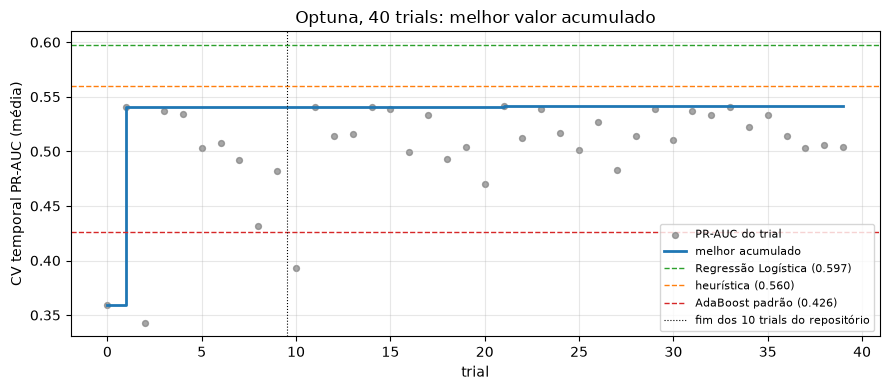

 number  value  melhor_acumulado
      0  0.359             0.359
      4  0.534             0.541
      9  0.482             0.541
     19  0.504             0.541
     29  0.538             0.542
     39  0.504             0.542


In [9]:
r_lr, r_h = resultados[(ALVO, "regressao_logistica")], resultados[(ALVO, "heuristica_recorrencia")]
r_pad = resultados[(ALVO, "adaboost_padrao")]
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(trials["number"], trials["value"], s=18, color="gray", alpha=.7, label="PR-AUC do trial")
ax.step(trials["number"], trials["melhor_acumulado"], where="post", color="C0", lw=2, label="melhor acumulado")
for r, nome, cor in [(r_lr, "Regressão Logística", "C2"), (r_h, "heurística", "C1"), (r_pad, "AdaBoost padrão", "C3")]:
    ax.axhline(r["cv_temporal_pr_auc_mean"], ls="--", lw=1, color=cor, label=f"{nome} ({r['cv_temporal_pr_auc_mean']:.3f})")
ax.axvline(9.5, color="k", lw=.8, ls=":", label="fim dos 10 trials do repositório")
ax.set(xlabel="trial", ylabel="CV temporal PR-AUC (média)", title="Optuna, 40 trials: melhor valor acumulado")
ax.legend(fontsize=8, loc="lower right")
salvar(fig, "optuna_melhor_acumulado.png")
print(trials[["number", "value", "melhor_acumulado"]].iloc[[0, 4, 9, 19, 29, n_feitos - 1]].to_string(index=False))

**Leitura.** A busca chega quase ao teto logo no começo. O trial 0 dá 0,359, o trial 1 já dá 0,541,
e o melhor dos 40 (trial 21) dá 0,542, só 0,001 a mais. Os 30 trials depois do 10º não mudam o
resultado de forma relevante. O melhor valor (0,542) fica 0,116 acima do AdaBoost padrão (0,426),
mas continua abaixo da heurística de recorrência (0,560, −0,018) e da Regressão Logística
(0,597, −0,055). Nenhum trial dentro do espaço `ESPACOS["adaboost"]` alcançou os pisos.

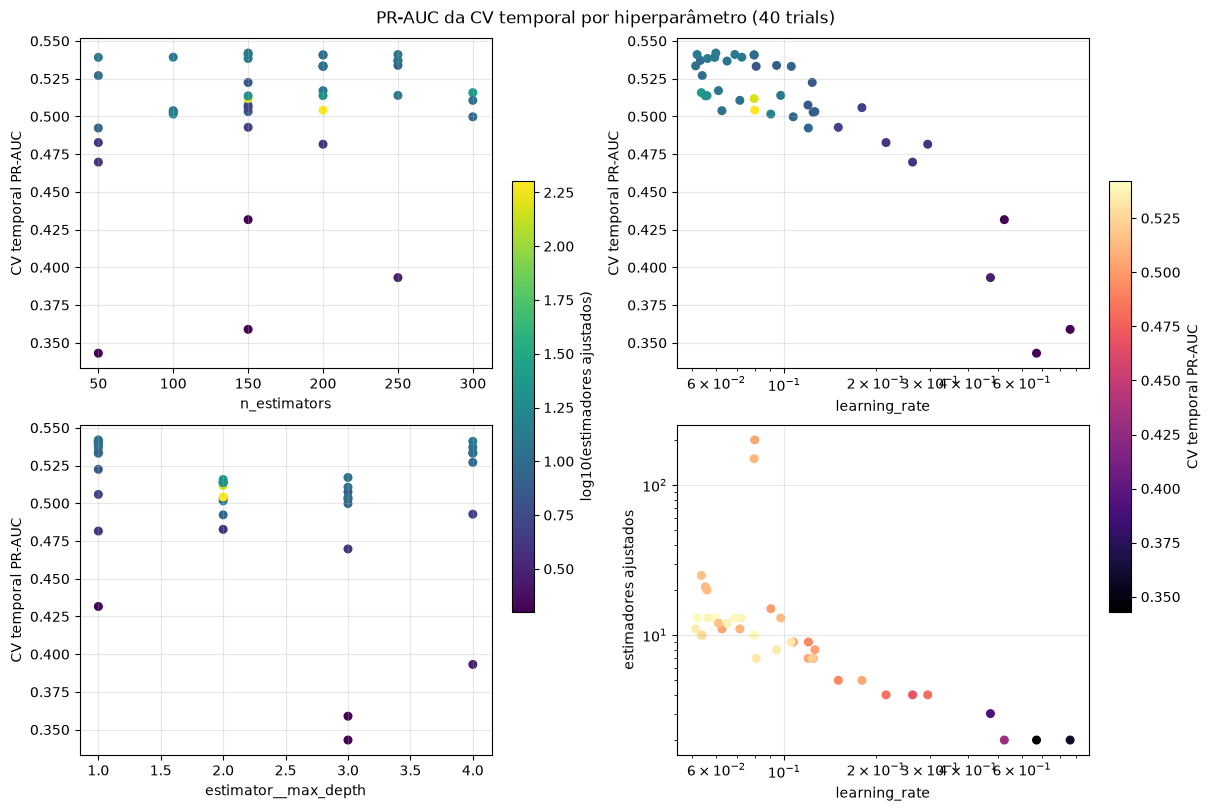

correlação de Spearman com o PR-AUC:
n_estimators             0.267
learning_rate           -0.751
estimator__max_depth    -0.326
estimadores_ajustados    0.573

PR-AUC médio por profundidade:
                      count   mean    max
estimator__max_depth                     
1                        14  0.523  0.542
2                        10  0.505  0.516
3                         9  0.468  0.517
4                         7  0.508  0.541


In [10]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
cor = np.log10(trials["estimadores_ajustados"])
for ax, p, log in zip(axs.flat[:3], ["n_estimators", "learning_rate", "estimator__max_depth"], [False, True, False]):
    sc = ax.scatter(trials[p], trials["value"], c=cor, cmap="viridis", s=30)
    ax.set(xlabel=p, ylabel="CV temporal PR-AUC", xscale="log" if log else "linear")
fig.colorbar(sc, ax=axs[:, 0], label="log10(estimadores ajustados)", shrink=.6)
sc2 = axs[1, 1].scatter(trials["learning_rate"], trials["estimadores_ajustados"], c=trials["value"], cmap="magma", s=30)
axs[1, 1].set(xscale="log", yscale="log", xlabel="learning_rate", ylabel="estimadores ajustados")
fig.colorbar(sc2, ax=axs[:, 1], label="CV temporal PR-AUC", shrink=.6)
fig.suptitle("PR-AUC da CV temporal por hiperparâmetro (40 trials)")
fig.savefig(FIG / "optuna_pr_auc_por_hiperparametro.png", dpi=110)
plt.show()
print("correlação de Spearman com o PR-AUC:")
print(trials[["n_estimators", "learning_rate", "estimator__max_depth", "estimadores_ajustados"]]
      .corrwith(trials["value"], method="spearman").round(3).to_string())
print("\nPR-AUC médio por profundidade:")
print(trials.groupby("estimator__max_depth")["value"].agg(["count", "mean", "max"]).round(3).to_string())

**Leitura.** O hiperparâmetro que mais pesa é o `learning_rate` (Spearman −0,751 com o PR-AUC):
quanto menor, melhor. Os bons trials ficam entre 0,05 e 0,08, perto do limite inferior do espaço.
Com taxa acima de 0,3, o melhor PR-AUC é 0,432. O mecanismo é o do painel de baixo à direita: a
taxa controla quantos estimadores o AdaBoost consegue ajustar antes de parar (Spearman +0,573 entre
estimadores ajustados e PR-AUC). Em 38 dos 40 trials, ele ajustou de 2 a 25 estimadores, não
importa o `n_estimators` pedido. Por isso, o `n_estimators` quase não importa (Spearman +0,267).
Só 2 trials (22 e 39, profundidade 2 e taxa 0,08) ajustaram todos os estimadores, e deram 0,512 e
0,504, abaixo do melhor. A profundidade 1 (stumps) tem a melhor média (0,523 em 14 trials) e o
melhor trial, mas a profundidade 4 também chega a 0,541. A diferença entre profundidades é menor
que a diferença causada pela taxa.

Como o melhor `learning_rate` está colado no limite inferior do espaço, o ótimo pode estar fora
dele. Mas o espaço é o do repositório, e mudá-lo quebraria a comparabilidade.

### Valeu ampliar de 10 para 40 trials?

O repositório usa 10 trials (`T.N_TRIALS`, seção 17.5). Rodo um estudo separado de 10 trials, com
a mesma semente e o mesmo objetivo, para comparar com os 40. A validação de 2023 dos dois melhores
é só reportada, sem registro no MLflow.

In [11]:
estudo10, tempo10 = estudar(10)
pipe10 = montar_pipeline(features, MODELO, **estudo10.best_params)
m10 = em_validacao(yv, clone(pipe10).fit(Xtr, ytr).predict_proba(Xv)[:, 1], tri_v)
comparacao_busca = pd.DataFrame({
    "10 trials (padrão do repositório)": {"tempo (s)": tempo10, "melhor trial": estudo10.best_trial.number,
                                          "CV temporal PR-AUC": estudo10.best_value, "Val PR-AUC": m10["pr_auc"],
                                          "Val Recall@50": m10["recall_at_50"], "params": estudo10.best_params},
    "40 trials": {"tempo (s)": tempo_busca, "melhor trial": melhor.number, "CV temporal PR-AUC": melhor.value,
                  "Val PR-AUC": m_otim["pr_auc"], "Val Recall@50": m_otim["recall_at_50"], "params": params_melhor},
}).T
print("os 10 primeiros trials dos 40 coincidem com o estudo de 10:",
      np.allclose(trials["value"].iloc[:10], [t.value for t in estudo10.trials]))
print(f"ganho de CV temporal PR-AUC com 40 trials: {melhor.value - estudo10.best_value:+.4f}")
comparacao_busca

os 10 primeiros trials dos 40 coincidem com o estudo de 10: True
ganho de CV temporal PR-AUC com 40 trials: +0.0013


,tempo (s),melhor trial,CV temporal PR-AUC,Val PR-AUC,Val Recall@50,params
10 trials (padrão do repositório),18.464,1,0.541,0.614,0.128,"{'n_estimators': 200, 'learning_rate': 0.07979..."
40 trials,114.493,21,0.542,0.614,0.128,"{'n_estimators': 150, 'learning_rate': 0.05974..."


**Leitura: ampliar para 40 trials não valeu.** Com a mesma semente, os 10 primeiros trials dos 40
são idênticos ao estudo de 10. O estudo de 10 achou o seu melhor já no trial 1 (0,541), e os 40
trials acrescentaram +0,0013 de PR-AUC na CV temporal, uma diferença bem menor que o desvio entre
folds (0,009 a 0,02). Na validação de 2023, as duas configurações dão o mesmo PR-AUC (0,614) e o
mesmo Recall@50 (0,128). O custo foi 6 vezes maior: 114 s contra 18 s. O tempo total ficou muito
abaixo do limite de 30 minutos, então não foi preciso reduzir os trials. Para o AdaBoost, o que
limita o resultado é o espaço de busca (e a parada precoce), não o número de trials.

## 6. Diagnóstico da melhor configuração

Curva de aprendizado com `metricas.curva_aprendizado` nos 4 folds temporais (fatias de 33%, 66% e
100% do treino de cada fold), e PR-AUC no próprio treino × CV temporal × validação 2023.

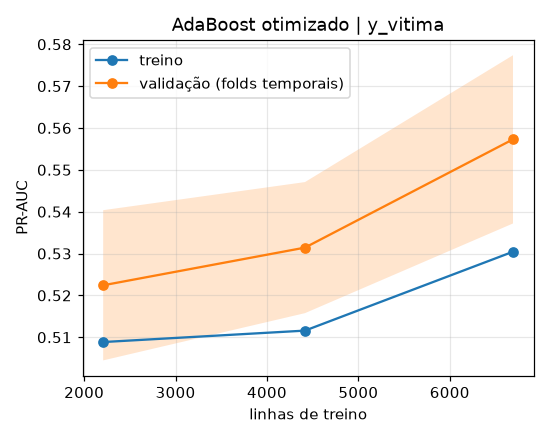

,linhas de treino,treino (média),validação dos folds (média),validação (desvio)
0,2208,0.509,0.522,0.018
1,4416,0.512,0.531,0.016
2,6692,0.530,0.557,0.020


In [12]:
from sklearn.model_selection import learning_curve

titulo_otim = f"AdaBoost otimizado | {ALVO}"
metricas.curva_aprendizado(clone(pipe_otim), Xtr, ytr, folds, FIG / "curva_aprendizado.png", titulo_otim)
display(Image(FIG / "curva_aprendizado.png"))
# os mesmos números da figura, para a leitura
tam, s_tr, s_va = learning_curve(clone(pipe_otim), Xtr, ytr, cv=folds, train_sizes=[0.33, 0.66, 1.0],
                                 scoring="average_precision", n_jobs=1)
pd.DataFrame({"linhas de treino": tam, "treino (média)": s_tr.mean(1), "validação dos folds (média)": s_va.mean(1),
              "validação (desvio)": s_va.std(1)}).round(3)

**Leitura: underfitting, não overfitting.** O PR-AUC no treino (0,509 → 0,530) fica *abaixo* do PR-AUC na
validação dos folds (0,522 → 0,557) em todos os tamanhos. Não há o gap treino > validação típico
de overfitting. Que a validação fique acima do treino se explica pela prevalência: as fatias de
treino começam em 2021 (14,1% de positivos), e os trimestres validados são de 2022 (13,7% a 16,7%).
As duas curvas sobem juntas com mais dados, e o nível (~0,53–0,56) fica abaixo do da Regressão
Logística. Isso indica viés alto: o modelo, com 13 stumps, é simples demais. Mais linhas ajudariam
pouco. O que mudaria o resultado é mais capacidade efetiva (mais estágios), que a parada precoce
impede (seção 7). O eixo x vai até 6.692 linhas porque o `learning_curve` usa como teto o menor
treino entre os folds (4 trimestres).

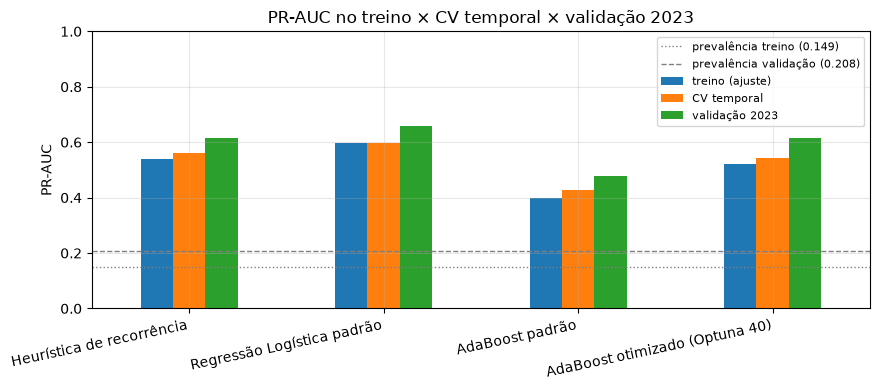

,treino (ajuste),CV temporal,validação 2023
Heurística de recorrência,0.540,0.560,0.614
Regressão Logística padrão,0.595,0.597,0.658
AdaBoost padrão,0.399,0.426,0.480
AdaBoost otimizado (Optuna 40),0.521,0.542,0.614


In [13]:
def treino_val(nome, pipe=None, score_fn=None):
    r = resultados[(ALVO, nome)]
    if pipe is not None:
        s = clone(pipe).fit(Xtr, ytr).predict_proba(Xtr)[:, 1]
    else:
        s = score_fn(partes["treino"])
    return {"treino (ajuste)": average_precision_score(ytr, s), "CV temporal": r["cv_temporal_pr_auc_mean"],
            "validação 2023": r["val_pr_auc"]}


tv = pd.DataFrame({
    NOMES["heuristica_recorrencia"]: treino_val("heuristica_recorrencia", score_fn=score_heuristica),
    NOMES["regressao_logistica"]: treino_val("regressao_logistica", montar_pipeline(features, "regressao_logistica")),
    NOMES["adaboost_padrao"]: treino_val("adaboost_padrao", montar_pipeline(features, MODELO)),
    NOMES["adaboost_otimizado"]: treino_val("adaboost_otimizado", pipe_otim),
}).T
fig, ax = plt.subplots(figsize=(9, 4))
tv.plot.bar(ax=ax)
ax.axhline(ytr.mean(), color="gray", ls=":", lw=1, label=f"prevalência treino ({ytr.mean():.3f})")
ax.axhline(yv.mean(), color="gray", ls="--", lw=1, label=f"prevalência validação ({yv.mean():.3f})")
ax.set(ylabel="PR-AUC", ylim=(0, 1), title="PR-AUC no treino × CV temporal × validação 2023")
ax.legend(fontsize=8)
plt.setp(ax.get_xticklabels(), rotation=12, ha="right")
salvar(fig, "pr_auc_treino_validacao.png")
tv.round(3)

**Leitura.** Em nenhum modelo o PR-AUC no próprio treino passa da CV temporal: AdaBoost otimizado
com 0,521 no treino, 0,542 na CV e 0,614 na validação; AdaBoost padrão com 0,399, 0,426 e 0,480.
Um modelo que decorasse o treino teria treino ≫ CV, e isso não acontece. A ordem treino < CV <
validação é a mesma da heurística, que não treina nada (0,540, 0,560, 0,614), e acompanha a
prevalência de cada parte (14,9% no treino, 15,6% em média nos folds, 20,8% em 2023). Então a
subida não é mérito do modelo. Comparando entre modelos na mesma parte, o AdaBoost otimizado
empata com a heurística na validação (0,614 contra 0,614) e fica 0,044 abaixo da Regressão
Logística (0,658).

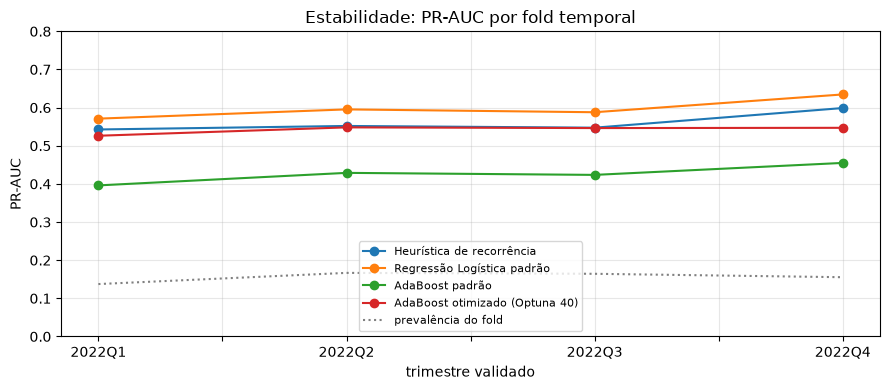

,Heurística de recorrência,Regressão Logística padrão,AdaBoost padrão,AdaBoost otimizado (Optuna 40),prevalência do fold
2022Q1,0.543,0.571,0.396,0.526,0.137
2022Q2,0.552,0.595,0.429,0.548,0.167
2022Q3,0.547,0.588,0.424,0.546,0.164
2022Q4,0.599,0.635,0.455,0.547,0.155
desvio (ddof=0),0.023,0.023,0.021,0.009,0.012


In [14]:
def por_fold(pipe=None, score=None):
    """PR-AUC em cada fold temporal (o _cv só devolve média e desvio)."""
    saida = []
    for tr, te in folds:
        s = score.iloc[te] if score is not None else clone(pipe).fit(Xtr.iloc[tr], ytr.iloc[tr]).predict_proba(Xtr.iloc[te])[:, 1]
        saida.append(average_precision_score(ytr.iloc[te], s))
    return saida


rotulos = [tri_tr[te][0] for _, te in folds]
folds_df = pd.DataFrame({
    NOMES["heuristica_recorrencia"]: por_fold(score=score_heuristica(partes["treino"])),
    NOMES["regressao_logistica"]: por_fold(montar_pipeline(features, "regressao_logistica")),
    NOMES["adaboost_padrao"]: por_fold(montar_pipeline(features, MODELO)),
    NOMES["adaboost_otimizado"]: por_fold(pipe_otim),
    "prevalência do fold": [ytr.iloc[te].mean() for _, te in folds],
}, index=rotulos)
fig, ax = plt.subplots(figsize=(9, 4))
folds_df.iloc[:, :4].plot(ax=ax, marker="o")
folds_df["prevalência do fold"].plot(ax=ax, color="gray", ls=":", label="prevalência do fold")
ax.set(xlabel="trimestre validado", ylabel="PR-AUC", ylim=(0, .8), title="Estabilidade: PR-AUC por fold temporal")
ax.legend(fontsize=8)
salvar(fig, "pr_auc_por_fold.png")
folds_df.loc["desvio (ddof=0)"] = folds_df.std(ddof=0)
folds_df.round(3)

**Leitura.** O AdaBoost otimizado é o mais estável entre os folds (desvio 0,009, contra 0,023 da
Regressão Logística e da heurística), mas é estável num nível mais baixo. Ele fica entre 0,526 e
0,548 e não acompanha a subida que os outros têm em 2022Q4 (Regressão Logística 0,635, heurística
0,599, AdaBoost otimizado 0,547). Em todo fold, ele fica abaixo da Regressão Logística (de −0,042 a
−0,088) e abaixo ou empatado com a heurística (de −0,001 a −0,052). Com poucos valores de score distintos,
o ranking do AdaBoost muda pouco de um trimestre para outro, o que explica tanto o desvio pequeno
quanto não aproveitar o trimestre mais fácil. O AdaBoost padrão fica abaixo de todos em todos os
folds (0,396 a 0,455).

## 7. Análise própria do AdaBoost

**PR-AUC da validação por estágio do boosting** (`staged_predict_proba`): um ponto por estimador
efetivamente ajustado. Como a Tabela 1 mostrou que o ajuste para cedo, entra junto um
**diagnóstico exploratório** definido aqui no notebook: a mesma configuração com a árvore base
**sem** `class_weight` (`estimator__class_weight=None`), para ver se a parada precoce é o que
limita o modelo. A variante não é registrada no MLflow, não entra nas tabelas e não concorre na
escolha: ela fica fora do espaço `ESPACOS["adaboost"]` e muda o tratamento de desbalanceamento
definido no `pipeline.modelos()`.

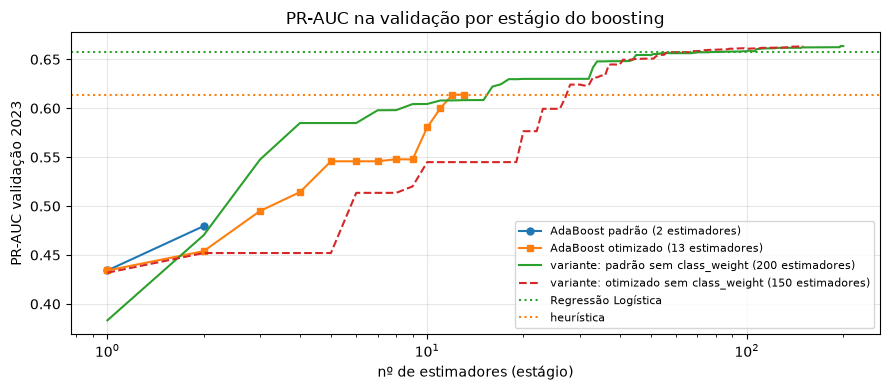

,estimadores pedidos,ajustados,scores distintos (val),Val PR-AUC,melhor estágio,PR-AUC no melhor estágio,CV temporal PR-AUC
modelo,,,,,,,
AdaBoost padrão,200,2,4,0.480,2,0.480,0.426
AdaBoost otimizado,150,13,39,0.614,12,0.614,0.542
variante: padrão sem class_weight,200,200,2733,0.664,198,0.664,0.603
variante: otimizado sem class_weight,150,150,1222,0.663,148,0.663,0.607


In [15]:
def pr_auc_por_estagio(pipe, X, y):
    Z = pipe.named_steps["prep"].transform(X)
    return [average_precision_score(y, p[:, 1]) for p in pipe.named_steps["modelo"].staged_predict_proba(Z)]


def adaboost_variante(**params):
    """Exploratório: árvore base sem class_weight (fora do espaço oficial, fora das tabelas)."""
    return montar_pipeline(features, MODELO, estimator__class_weight=None, **params)


pipe_pad_fit = montar_pipeline(features, MODELO).fit(Xtr, ytr)
variantes = {
    "AdaBoost padrão": pipe_pad_fit,
    "AdaBoost otimizado": pipe_otim,  # já ajustado no treino pelo _rodar
    "variante: padrão sem class_weight": adaboost_variante().fit(Xtr, ytr),
    "variante: otimizado sem class_weight": adaboost_variante(**params_melhor).fit(Xtr, ytr),
}
estagios = {n: pr_auc_por_estagio(p, Xv, yv) for n, p in variantes.items()}
fig, ax = plt.subplots(figsize=(9, 4))
for (n, v), est in zip(estagios.items(), ["o-", "s-", "-", "--"]):
    ax.plot(range(1, len(v) + 1), v, est, ms=5, label=f"{n} ({len(v)} estimadores)")
ax.axhline(resultados[(ALVO, "regressao_logistica")]["val_pr_auc"], color="C2", ls=":", label="Regressão Logística")
ax.axhline(resultados[(ALVO, "heuristica_recorrencia")]["val_pr_auc"], color="C1", ls=":", label="heurística")
ax.set(xscale="log", xlabel="nº de estimadores (estágio)", ylabel="PR-AUC validação 2023",
       title="PR-AUC na validação por estágio do boosting")
ax.legend(fontsize=8)
salvar(fig, "pr_auc_por_estagio.png")

diag = []
for n, p in variantes.items():
    mod = p.named_steps["modelo"]
    s = p.predict_proba(Xv)[:, 1]
    linha_d = {"modelo": n, "estimadores pedidos": mod.n_estimators, "ajustados": len(mod.estimators_),
               "scores distintos (val)": len(np.unique(s.round(10))), "Val PR-AUC": average_precision_score(yv, s),
               "melhor estágio": int(np.argmax(estagios[n])) + 1, "PR-AUC no melhor estágio": max(estagios[n])}
    if n.startswith("variante"):  # CV temporal da variante, para não ler a validação sozinha
        linha_d["CV temporal PR-AUC"] = _cv(p, Xtr, ytr, folds)["cv_temporal_pr_auc_mean"]
    else:
        linha_d["CV temporal PR-AUC"] = resultados[(ALVO, "adaboost_padrao" if "padrão" in n else "adaboost_otimizado")]["cv_temporal_pr_auc_mean"]
    diag.append(linha_d)
pd.DataFrame(diag).set_index("modelo").round(3)

**Leitura.** Este é o achado principal do notebook.

- Nas configurações oficiais, o AdaBoost para cedo: o padrão ajusta **2** de 200 estimadores, e o
  otimizado, **13** de 150. A curva do otimizado sobe em degraus (0,435 → 0,614) e é cortada
  ainda subindo: o melhor estágio é o 12º de 13. Mais estágios ajudariam, mas o
  SAMME não os ajusta: com `class_weight="balanced"` na árvore base, o erro ponderado chega a 0,5 ou
  mais depois de poucas rodadas.
- A variante exploratória **sem** `class_weight` ajusta todos os estimadores pedidos (200 e 150).
  O score passa a ter de 1.222 a 2.733 valores distintos, contra 4 a 39, e a curva continua subindo
  até ~0,66 na validação. Na CV temporal, as variantes dão 0,603 e 0,607, contra 0,426 e 0,542 das
  oficiais, e ficam no nível da Regressão Logística (0,597): +0,006 a +0,010, menos que um desvio
  entre folds (0,023).
- Ressalvas: a variante está fora do espaço `ESPACOS["adaboost"]`, foi vista depois da busca e não
  foi otimizada nem validada de forma independente. Ela é evidência de que a limitação vem da
  combinação `class_weight` + SAMME, e não um resultado a ser comparado com o do grupo. Mudar
  `pipeline.modelos()` é decisão para o grupo, fora deste notebook.

atributos com importância > 0: 5 de 142 colunas depois do pré-processamento


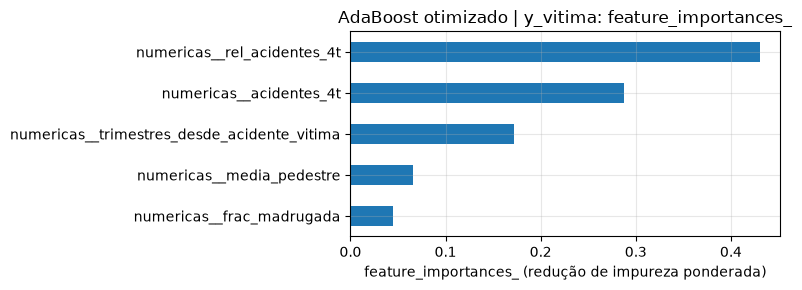

,importância
numericas__rel_acidentes_4t,0.430
numericas__acidentes_4t,0.287
numericas__trimestres_desde_acidente_vitima,0.172
numericas__media_pedestre,0.065
numericas__frac_madrugada,0.045


In [16]:
nomes_prep = pipe_otim.named_steps["prep"].get_feature_names_out()
fi = pd.Series(pipe_otim.named_steps["modelo"].feature_importances_, index=nomes_prep).sort_values(ascending=False)
print(f"atributos com importância > 0: {(fi > 0).sum()} de {len(fi)} colunas depois do pré-processamento")
top_fi = fi[fi > 0].head(20)
fig, ax = plt.subplots(figsize=(8, max(3, .35 * len(top_fi))))
top_fi.iloc[::-1].plot.barh(ax=ax)
ax.set(xlabel="feature_importances_ (redução de impureza ponderada)", title=f"{titulo_otim}: feature_importances_")
salvar(fig, "feature_importances.png")
top_fi.round(4).to_frame("importância")

**Leitura.** Com 13 stumps, só **5 de 142** colunas depois do pré-processamento recebem importância
maior que zero. Todas são numéricas de histórico ou perfil do local: `rel_acidentes_4t` (0,430),
`acidentes_4t` (0,287), `trimestres_desde_acidente_vitima` (0,172), `media_pedestre` (0,065) e
`frac_madrugada` (0,045). Nenhuma categórica de via, contexto ou bairro é usada. As três primeiras
somam 89% da importância e são, em essência, a mesma informação que a heurística de recorrência usa
(histórico recente de acidentes). Isso é coerente com o AdaBoost otimizado empatar com ela na
validação. A `feature_importances_` vem da redução de impureza no treino e não diz quanto cada
atributo melhora o ranking. Para isso, a seguir vem a importância por permutação.

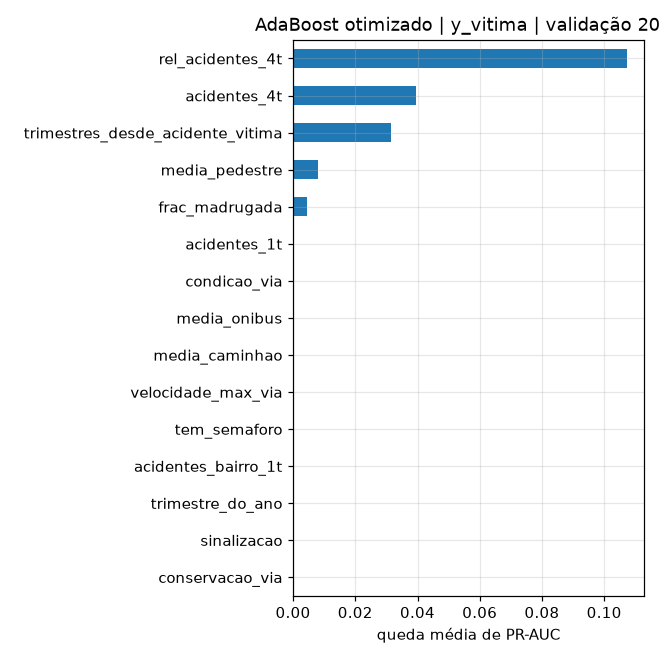

atributos com queda de PR-AUC > 0: 5 de 48


,queda média de PR-AUC
rel_acidentes_4t,0.107
acidentes_4t,0.039
trimestres_desde_acidente_vitima,0.032
media_pedestre,0.008
frac_madrugada,0.004
acidentes_1t,0.000
condicao_via,0.000
media_onibus,0.000
media_caminhao,0.000
velocidade_max_via,0.000


In [17]:
_, imp_perm = metricas.importancia_permutacao(pipe_otim, Xv, yv, FIG / "permutation_importance.png",
                                              f"{titulo_otim} | validação 2023", top=15)
display(Image(FIG / "permutation_importance.png"))
print(f"atributos com queda de PR-AUC > 0: {(imp_perm > 0).sum()} de {len(imp_perm)}")
imp_perm.head(15).round(4).to_frame("queda média de PR-AUC")

**Leitura.** A permutação na validação de 2023 confirma a mesma lista. Só 5 dos 48 atributos de
entrada derrubam o PR-AUC quando embaralhados: `rel_acidentes_4t` (−0,107), `acidentes_4t`
(−0,039), `trimestres_desde_acidente_vitima` (−0,032), `media_pedestre` (−0,008) e `frac_madrugada`
(−0,004). Os outros 43 têm queda zero, porque o modelo não os usa. O top 15 da tabela, depois do
5º, é só ordem de empate em zero. A participação relativa nos últimos 4 trimestres sozinha responde
pela maior parte do desempenho, e isso é coerente com a decisão da seção 3.2 de ter features
relativas, imunes à mudança de patamar do registro.

## 8. Erros na validação de 2023

Os 10 maiores falsos positivos (sem acidente com vítima no trimestre seguinte, mas com os maiores
scores) e os 10 maiores falsos negativos (com acidente, mas com os menores scores), da melhor
configuração. `trimestre` é o trimestre da linha (das features); o alvo é o trimestre seguinte.

In [18]:
from src.comum.db import engine

dim = pd.read_sql_table("dim_local", engine())[["local_id", "bairro", "logradouro"]]
score_otim = pipe_otim.predict_proba(Xv)[:, 1]
erros = (partes["validacao"][["local_id", "trimestre", "acidentes_vitima_4t", "acidentes_4t", ALVO]]
         .assign(score=score_otim).merge(dim, on="local_id", how="left"))
erros["trimestre_alvo"] = (pd.PeriodIndex(erros["trimestre"], freq="Q") + 1).astype(str)
colunas = ["bairro", "logradouro", "trimestre", "trimestre_alvo", "score", "acidentes_vitima_4t", "acidentes_4t"]
fp = erros[erros[ALVO] == 0].sort_values("score", ascending=False, kind="stable")
fn = erros[erros[ALVO] == 1].sort_values("score", kind="stable")
print(f"limiar (F1 na validação): {m_otim['limiar']:.4f} | FP: {int(m_otim['fp'])} | FN: {int(m_otim['fn'])}")
print(f"negativos empatados no maior score: {(fp['score'] == fp['score'].iloc[0]).sum()} | "
      f"positivos empatados no menor score: {(fn['score'] == fn['score'].iloc[0]).sum()}")
print("\n10 maiores falsos positivos")
display(fp[colunas].head(10).reset_index(drop=True))
print("10 maiores falsos negativos")
display(fn[colunas].head(10).reset_index(drop=True))
print("histórico médio (acidentes_vitima_4t) | todos os negativos:",
      round(erros.loc[erros[ALVO] == 0, "acidentes_vitima_4t"].mean(), 2),
      "| todos os positivos:", round(erros.loc[erros[ALVO] == 1, "acidentes_vitima_4t"].mean(), 2))

limiar (F1 na validação): 0.4107 | FP: 528 | FN: 593
negativos empatados no maior score: 61 | positivos empatados no menor score: 177

10 maiores falsos positivos


,bairro,logradouro,trimestre,trimestre_alvo,score,acidentes_vitima_4t,acidentes_4t
0,BOA VISTA,RUA DO HOSPICIO,2023Q1,2023Q2,0.881,3,6
1,BOA VISTA,RUA DO PRINCIPE,2023Q1,2023Q2,0.881,5,6
2,IMBIRIBEIRA,RUA JOAQUIM BANDEIRA,2023Q1,2023Q2,0.881,5,6
3,ESPINHEIRO,RUA DO ESPINHEIRO,2023Q1,2023Q2,0.881,6,7
4,BOA VIAGEM,RUA BARAO DE SOUZA LEAO,2023Q1,2023Q2,0.881,6,8
5,BOMBA DO HEMETÉRIO,RUA BOMBA DO HEMETERIO,2023Q1,2023Q2,0.881,5,5
6,ESPINHEIRO,RUA CONS PORTELA,2023Q1,2023Q2,0.881,6,6
7,BOA VISTA,RUA AURORA,2023Q1,2023Q2,0.881,5,5
8,SÃO JOSÉ,RUA IMPERIAL,2023Q1,2023Q2,0.881,12,17
9,BONGI,EST DO BONGI,2023Q1,2023Q2,0.881,4,5


10 maiores falsos negativos


,bairro,logradouro,trimestre,trimestre_alvo,score,acidentes_vitima_4t,acidentes_4t
0,CORDEIRO,RUA TAMBORIL,2023Q1,2023Q2,0.119,0,0
1,AFOGADOS,RUA AUGUSTO CALHEIROS,2023Q1,2023Q2,0.119,0,0
2,SÃO JOSÉ,RUA DO FORTE,2023Q1,2023Q2,0.119,0,0
3,PINA,RUA NOGUEIRA DE SOUZA,2023Q1,2023Q2,0.119,0,0
4,JORDÃO,RUA NOVA CANAA,2023Q1,2023Q2,0.119,0,0
5,BOA VISTA,RUA DOS COELHOS,2023Q1,2023Q2,0.119,0,0
6,ESTÂNCIA,RUA MORAIS E SILVA,2023Q1,2023Q2,0.119,0,0
7,TORRE,RUA JOAO TUDE DE MELO,2023Q1,2023Q2,0.119,0,0
8,CASA AMARELA,RUA FERREIRA LOPES,2023Q1,2023Q2,0.119,0,0
9,GRAÇAS,RUA JOAO RAMOS,2023Q1,2023Q2,0.119,0,0


histórico médio (acidentes_vitima_4t) | todos os negativos: 0.47 | todos os positivos: 4.83


**Leitura.** Os "10 maiores" de cada lado precisam ser lidos com uma ressalva. Como o score tem
poucos valores distintos (39), **61** negativos empatam no maior score (0,881) e **177** positivos
empatam no menor (0,119). Os 10 mostrados são só os primeiros de cada empate na ordem estável da
tabela (2023Q1 e `local_id`), e não "os piores" em sentido estrito.

- **Falsos positivos:** locais com histórico alto (3 a 12 acidentes com vítima nos últimos 4
  trimestres, como a Rua Imperial em São José, com 12 de 17) que não tiveram acidente com vítima no
  trimestre seguinte. É o erro natural de um ranking por recorrência: um trimestre sem registro num
  local que costuma ter acidentes.
- **Falsos negativos:** todos têm **zero** acidentes nos últimos 4 trimestres e caem no menor score
  possível. Nada nas features que o modelo usa distingue esses locais dos outros locais sem
  histórico recente. Entre todas as linhas da validação, a média de `acidentes_vitima_4t` é 4,83
  nos positivos e 0,47 nos negativos. O modelo acerta essa tendência geral, mas não tem como
  antecipar o primeiro acidente de um local "quieto".

## 9. Alvo secundário: `y_atropelamento`

A melhor configuração (escolhida em `y_vitima`) reavaliada em `y_atropelamento`, com as mesmas
partes e os mesmos folds temporais, ao lado dos pisos e do AdaBoost padrão. Ressalva
(`ARCHITECTURE.md`, seção 17.2): o alvo tem pouquíssimos positivos (cerca de 30 a 50 por
trimestre), então o PR-AUC de cada fold oscila muito e diferenças pequenas não querem dizer nada.

No MLflow, só a melhor configuração reavaliada vira run (experimento 03, `busca=optuna_40`,
`alvo=y_atropelamento`). Os pisos e o padrão neste alvo são calculados sem registro.

In [19]:
ALVO2 = "y_atropelamento"
partes2, folds2 = preparar(ALVO2)
Xtr2, ytr2 = _xy(partes2["treino"], ALVO2)
Xv2, yv2 = _xy(partes2["validacao"], ALVO2)
tri2 = partes2["treino"]["trimestre"].to_numpy()
print(f"positivos: treino {ytr2.sum()} ({ytr2.mean():.4f}) | validação {yv2.sum()} ({yv2.mean():.4f})")
print("positivos na validação de cada fold:", {tri2[te][0]: int(ytr2.iloc[te].sum()) for _, te in folds2})
print("positivos por trimestre na validação 2023:", partes2["validacao"].groupby("trimestre")[ALVO2].sum().to_dict())

for nome, r in pisos(ALVO2, partes2, folds2).items():
    resultados[(ALVO2, nome)] = r
pad2 = montar_pipeline(features, MODELO)
cv_pad2 = {**_cv(pad2, Xtr2, ytr2, folds2), **_cv_estratificado(pad2, Xtr2, ytr2)}
resultados[(ALVO2, "adaboost_padrao")] = linha(
    cv_pad2, em_validacao(yv2, clone(pad2).fit(Xtr2, ytr2).predict_proba(Xv2)[:, 1], partes2["validacao"]["trimestre"]))

pipe_otim2 = montar_pipeline(features, MODELO, **params_melhor)
cv_otim2 = {**_cv(pipe_otim2, Xtr2, ytr2, folds2), **_cv_estratificado(pipe_otim2, Xtr2, ytr2)}
run_otim2, m_otim2 = _rodar(f"{MODELO}_optuna40_melhor", ALVO2, pipe_otim2, partes2, params_melhor, cv_otim2,
                            {"etapa": "otimizacao", "busca": "optuna_40", **TAGS}, folds2)
resultados[(ALVO2, "adaboost_otimizado")] = linha(cv_otim2, m_otim2, run_otim2)
print("run", run_otim2)
tabela(ALVO2, ["heuristica_recorrencia", "regressao_logistica", "adaboost_padrao", "adaboost_otimizado"])

positivos: treino 313 (0.0234) | validação 151 (0.0226)
positivos na validação de cada fold: {'2022Q1': 46, '2022Q2': 48, '2022Q3': 44, '2022Q4': 42}
positivos por trimestre na validação 2023: {'2023Q1': 40.0, '2023Q2': 40.0, '2023Q3': 36.0, '2023Q4': 35.0}


2026/11/23 14:13:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run adaboost_optuna40_melhor at: http://mlflow:5000/#/experiments/2/runs/0d87f376a9504969a038b98c2cd4c532
🧪 View experiment at: http://mlflow:5000/#/experiments/2
run 0d87f376a9504969a038b98c2cd4c532


,CV temporal PR-AUC,CV temporal ROC-AUC,CV estratificado PR-AUC,Δ PR-AUC estrat. − temporal,Val PR-AUC,Val Recall@50,Val Recall@100,Val ROC-AUC
Heurística de recorrência,0.318 ± 0.016,0.841 ± 0.023,0.272 ± 0.050,-0.046,0.290,0.424,0.562,0.828
Regressão Logística padrão,0.303 ± 0.018,0.818 ± 0.013,0.274 ± 0.064,-0.029,0.278,0.418,0.558,0.823
AdaBoost padrão,0.140 ± 0.016,0.828 ± 0.028,0.112 ± 0.014,-0.028,0.127,0.268,0.485,0.825
AdaBoost otimizado (Optuna 40),0.190 ± 0.025,0.862 ± 0.031,0.155 ± 0.014,-0.035,0.141,0.293,0.521,0.828


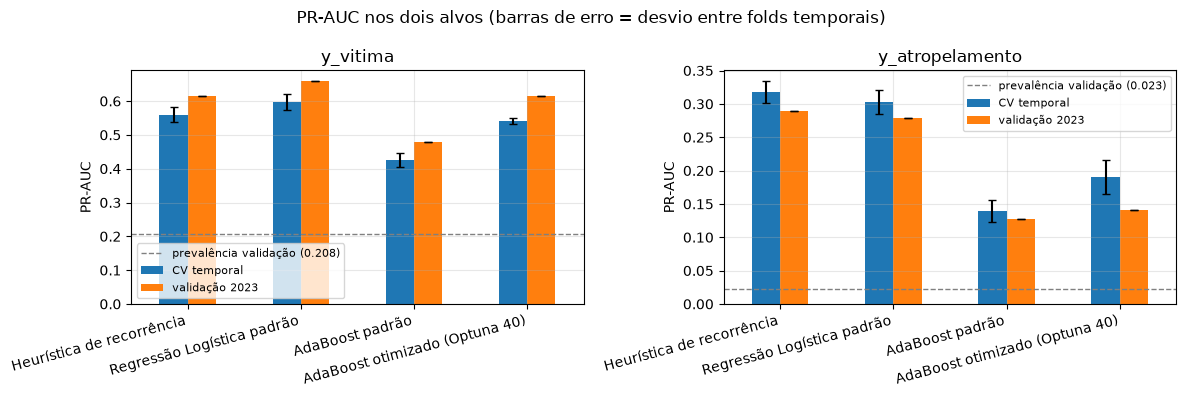

In [20]:
ordem = ["heuristica_recorrencia", "regressao_logistica", "adaboost_padrao", "adaboost_otimizado"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, alvo, prev in [(axs[0], ALVO, yv.mean()), (axs[1], ALVO2, yv2.mean())]:
    vals = pd.DataFrame({NOMES[n]: {"CV temporal": resultados[(alvo, n)]["cv_temporal_pr_auc_mean"],
                                    "validação 2023": resultados[(alvo, n)]["val_pr_auc"]} for n in ordem}).T
    erro = pd.DataFrame({"CV temporal": [resultados[(alvo, n)]["cv_temporal_pr_auc_std"] for n in ordem],
                         "validação 2023": 0}, index=vals.index)
    vals.plot.bar(ax=ax, yerr=erro, capsize=3)
    ax.axhline(prev, color="gray", ls="--", lw=1, label=f"prevalência validação ({prev:.3f})")
    ax.set(title=alvo, ylabel="PR-AUC")
    ax.legend(fontsize=8)
    plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
fig.suptitle("PR-AUC nos dois alvos (barras de erro = desvio entre folds temporais)")
salvar(fig, "pr_auc_dois_alvos.png")

**Leitura** (com a ressalva da seção 17.2: de 42 a 48 positivos por fold e de 35 a 40 por trimestre
de 2023, 151 na validação inteira).

- Em `y_atropelamento`, a **heurística de recorrência é a melhor** em PR-AUC: 0,318 na CV temporal e
  0,290 na validação, contra 0,303 e 0,278 da Regressão Logística. O AdaBoost otimizado em
  `y_vitima` fica bem abaixo neste alvo: 0,190 na CV (−0,128 contra a heurística) e 0,141 na
  validação (−0,149). O padrão fica ainda mais baixo (0,140 e 0,127). Todos ficam acima da
  prevalência (0,023).
- O ROC-AUC conta outra história: o AdaBoost otimizado tem o maior ROC-AUC na CV (0,862 ± 0,031) e
  empata na validação (0,828). Ele separa bem os locais de risco baixo dos demais, mas o topo da
  lista, que é o que importa para a CTTU, tem muitos empates e precisão baixa. O Recall@50 na
  validação confirma: 0,293 do AdaBoost otimizado contra 0,424 da heurística.
- Os hiperparâmetros vieram da busca em `y_vitima`. Não houve busca própria para este alvo, então
  este resultado mede a transferência da configuração, não o melhor AdaBoost possível para
  atropelamento. Com tão poucos positivos, diferenças de 0,01 a 0,02 entre a heurística e a
  Regressão Logística estão dentro do ruído (desvio de 0,016 a 0,018). Já a diferença para o
  AdaBoost (~0,13) é grande demais para ser só ruído.

## 10. Tabela final e exportação

In [21]:
NOMES_ALVO = {"y_vitima": "y_vitima (principal)", "y_atropelamento": "y_atropelamento (secundário)"}
tabela2 = pd.concat({NOMES_ALVO[a]: tabela(a, ordem) for a in (ALVO, ALVO2)})
tabela2.index.names = ["alvo", "modelo"]
tabela2

CV temporal PR-AUC CV temporal ROC-AUC CV estratificado PR-AUC Δ PR-AUC estrat. − temporal Val PR-AUC Val Recall@50  \
alvo                         modelo                                                                                                                                               
y_vitima (principal)         Heurística de recorrência           0.560 ± 0.023       0.790 ± 0.016           0.541 ± 0.021                      -0.019      0.614         0.141   
                             Regressão Logística padrão          0.597 ± 0.023       0.816 ± 0.017           0.578 ± 0.020                      -0.019      0.658         0.141   
                             AdaBoost padrão                     0.426 ± 0.021       0.789 ± 0.015           0.402 ± 0.021                      -0.024      0.480         0.091   
                             AdaBoost otimizado (Optuna 40)      0.542 ± 0.009       0.811 ± 0.015           0.517 ± 0.024                      -0.025      0.614         0.128   
y_atropelamento (secundário) Heurística de recorrência           0.318 ± 0.016       0.841 ± 0.023           0.272 ± 0.050                      -0.046      0.290         0.424   
                             Regressão Logística padrão          0.303 ± 0.018       0.818 ± 0.013           0.274 ± 0.064                      -0.029      0.278         0.418   
                             AdaBoost padrão                     0.140 ± 0.016       0.828 ± 0.028           0.112 ± 0.014                      -0.028      0.127         0.268   
                             AdaBoost otimizado (Optuna 40)      0.190 ± 0.025       0.862 ± 0.031           0.155 ± 0.014                      -0.035      0.141         0.293   

                                                            Val Recall@100 Val ROC-AUC  
alvo                         modelo                                                     
y_vitima (principal)         Heurística de recorrência               0.261       0.795  
                             Regressão Logística padrão              0.264       0.818  
                             AdaBoost padrão                         0.188       0.775  
                             AdaBoost otimizado (Optuna 40)          0.252       0.810  
y_atropelamento (secundário) Heurística de recorrência               0.562       0.828  
                             Regressão Logística padrão              0.558       0.823  
                             AdaBoost padrão                         0.485       0.825  
                             AdaBoost otimizado (Optuna 40)          0.521       0.828

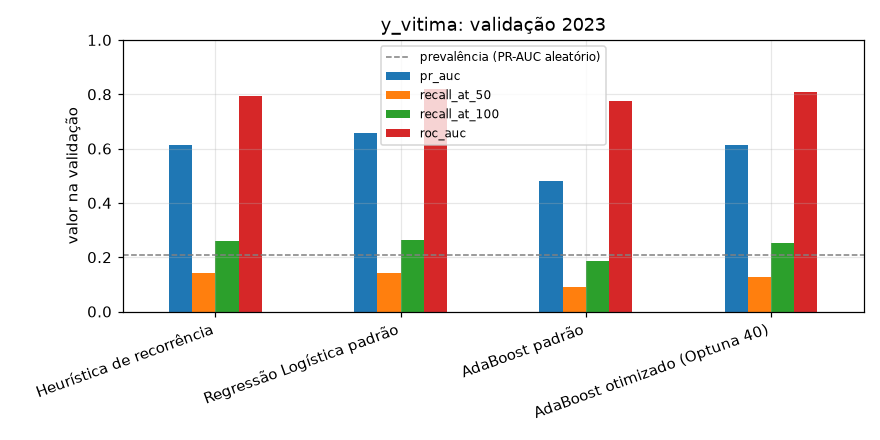

gravado: reports/experimentos/marina_adaboost.csv
figuras: ['comparacao_validacao_y_vitima.png', 'curva_aprendizado.png', 'feature_importances.png', 'optuna_melhor_acumulado.png', 'optuna_pr_auc_por_hiperparametro.png', 'permutation_importance.png', 'pr_auc_dois_alvos.png', 'pr_auc_por_estagio.png', 'pr_auc_por_fold.png', 'pr_auc_treino_validacao.png']


In [22]:
colunas_csv = ["cv_temporal_pr_auc_mean", "cv_temporal_pr_auc_std", "cv_temporal_roc_auc_mean", "cv_temporal_roc_auc_std",
               "cv_estratificado_pr_auc_mean", "cv_estratificado_pr_auc_std", "val_pr_auc", "val_recall_at_50",
               "val_recall_at_100", "val_roc_auc", "val_prevalencia", "val_limiar", "val_f1", "val_precisao", "val_recall"]
csv = pd.DataFrame([{"autor": AUTOR, "modelo_investigado": MODELO, "alvo": a, "configuracao": n,
                     **{c: resultados[(a, n)].get(c) for c in colunas_csv},
                     "params": str(params_melhor) if n == "adaboost_otimizado" else
                               ("pipeline.modelos()" if n != "heuristica_recorrencia" else "acidentes_vitima_4t + acidentes_4t/1000"),
                     "run_id_mlflow": resultados[(a, n)].get("run_id")}
                    for a in (ALVO, ALVO2) for n in ordem])
csv["tempo_busca_optuna_s"] = round(tempo_busca, 1)
csv["n_trials_optuna"] = n_feitos
csv.to_csv(EXP / f"{AUTOR}_{MODELO}.csv", index=False)

barras = pd.DataFrame({NOMES[n]: {k.removeprefix("val_"): resultados[(ALVO, n)][k] for k in
                                  ["val_pr_auc", "val_recall_at_50", "val_recall_at_100", "val_roc_auc", "val_prevalencia"]}
                       for n in ordem}).T
metricas.barras_comparacao(barras, FIG / "comparacao_validacao_y_vitima.png", f"{ALVO}: validação 2023")
display(Image(FIG / "comparacao_validacao_y_vitima.png"))
print("gravado:", (EXP / f"{AUTOR}_{MODELO}.csv").relative_to(RAIZ))
print("figuras:", sorted(p.name for p in FIG.glob("*.png")))

**Leitura.** Na validação de 2023 (`y_vitima`), o AdaBoost otimizado recupera a maior parte da
distância entre o padrão e os pisos: PR-AUC de 0,480 para 0,614 e Recall@100 de 0,188 para 0,252.
Ainda assim, ele empata com a heurística em PR-AUC (0,614 contra 0,614) e perde em Recall@50 (0,128
contra 0,141) e Recall@100 (0,252 contra 0,261). Contra a Regressão Logística, perde em todas as
métricas.

## Conclusões

- **Desempenho.** Em `y_vitima`, a melhor configuração do AdaBoost (Optuna com 40 trials, escolhida
  pela CV temporal: `n_estimators=150`, `learning_rate≈0,060`, `max_depth=1`) tem PR-AUC de
  **0,542 ± 0,009** na CV temporal e **0,614** na validação de 2023, com Recall@50 de 0,128,
  Recall@100 de 0,252 e ROC-AUC de 0,810. O AdaBoost padrão do repositório tem 0,426 e 0,480.
- **Contra a Regressão Logística: perdeu.** −0,055 de PR-AUC na CV temporal (0,542 contra 0,597),
  −0,044 na validação (0,614 contra 0,658) e −0,013 de Recall@50 (0,128 contra 0,141).
- **Contra a heurística de recorrência: não ganhou.** −0,018 na CV temporal (0,542 contra 0,560),
  empate na validação (0,6139 contra 0,6138) e −0,013 de Recall@50. Pelo critério da seção 17.9, o
  AdaBoost, como está configurado no repositório, não acrescenta nada à heurística da CTTU.
- **Alvo secundário:** em `y_atropelamento`, o AdaBoost também fica abaixo dos dois pisos em PR-AUC
  (0,190 contra 0,318 da heurística na CV), com a ressalva dos poucos positivos.
- **Por quê.** O ajuste para depois de 2 (padrão) ou 13 (otimizado) estimadores, por causa de
  `class_weight="balanced"` na árvore base com o SAMME. O modelo vira um punhado de stumps sobre o
  histórico recente do local, com poucos valores de score e muitos empates. A curva de aprendizado
  indica underfitting, não overfitting.
- **Busca.** Ampliar de 10 para 40 trials custou 6 vezes mais tempo (114 s contra 18 s) e rendeu
  +0,001 de PR-AUC na CV temporal. Não valeu.
- **Exploratório (fora das tabelas).** Sem `class_weight` na árvore base, o AdaBoost ajusta todos os
  estimadores e chega a ~0,60 na CV temporal, no nível da Regressão Logística. Vale o grupo decidir
  se a configuração em `pipeline.modelos()` deve mudar. Isso está fora do escopo deste notebook.